# Taller 1: Teoría de Aprendizaje de Máquina (2026-2)

**Profesor:** Diego Armando Pérez Rosero · **Estudiante:** Juan Fernando Montoya Ortiz

**Tema:** clasificación supervisada, vecinos cercanos y evaluación de modelos.

| Punto | Qué se resuelve |
|---|---|
| 1. Perceptrón | Frontera de decisión, demostración del cambio de margen y una actualización numérica |
| 2. k-NN | Clasificación manual de $q=(1,1)$, implementación con `make_moons` y elección de $k$ |
| 3. Evaluación | Matriz de confusión, métricas a mano y su verificación con scikit-learn |

Cada punto tiene el cálculo manual que pide el enunciado y el código que lo comprueba. Todas las partes aleatorias usan la semilla `SEMILLA = 42`, la misma que pide el enunciado para `make_moons`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)
import sklearn

SEMILLA = 42
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "0.35"
FONDO = ListedColormap(["#d6e4f7", "#fbe0d3"])      # regiones: clase 0 / −1 / A en azul, clase 1 / +1 / B en naranja
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", "{:.4f}".format)
print(f"numpy {np.__version__} · scikit-learn {sklearn.__version__}")

numpy 2.5.3 · scikit-learn 1.9.1


# Punto 1. Clasificación lineal y algoritmo del perceptrón

El clasificador asigna

$$\hat y=\begin{cases}+1,& w^\top x+b>0,\\-1,& w^\top x+b\le 0,\end{cases}\qquad w\in\mathbb R^2,\ b\in\mathbb R .$$

Ojo con el caso $w^\top x+b=0$: la regla lo manda a la clase $-1$. Eso importa en el punto 1.3.

## 1.1 Frontera de decisión

Con $w=[1,2]^\top$ y $b=-3$, la frontera es el conjunto de puntos donde $w^\top x+b=0$:

$$x_1+2x_2-3=0\quad\Longleftrightarrow\quad x_2=\frac{3-x_1}{2}=1.5-0.5\,x_1 .$$

Es una recta con pendiente $-0.5$ que corta los ejes en $(3,0)$ y $(0,1.5)$. El vector $w=[1,2]^\top$ es perpendicular a ella y apunta hacia la región $+1$.

| Punto | $w^\top x+b$ | Signo | Clase |
|---|---|---|---|
| $x_1=(0,0)$ | $0+0-3=-3$ | $\le0$ | $-1$ |
| $x_2=(1,0)$ | $1+0-3=-2$ | $\le0$ | $-1$ |
| $x_3=(2,1)$ | $2+2-3=1$ | $>0$ | $+1$ |
| $x_4=(3,1)$ | $3+2-3=2$ | $>0$ | $+1$ |

El valor $w^\top x+b$ dice de qué lado de la recta queda el punto, y su magnitud es proporcional a la distancia: la distancia con signo es $\frac{w^\top x+b}{\|w\|}$, con $\|w\|=\sqrt5$.

,x,wᵀx + b,distancia con signo,clase
x1,"(0, 0)",-3.0000,-1.3416,-1
x2,"(1, 0)",-2.0000,-0.8944,-1
x3,"(2, 1)",1.0000,0.4472,1
x4,"(3, 1)",2.0000,0.8944,1


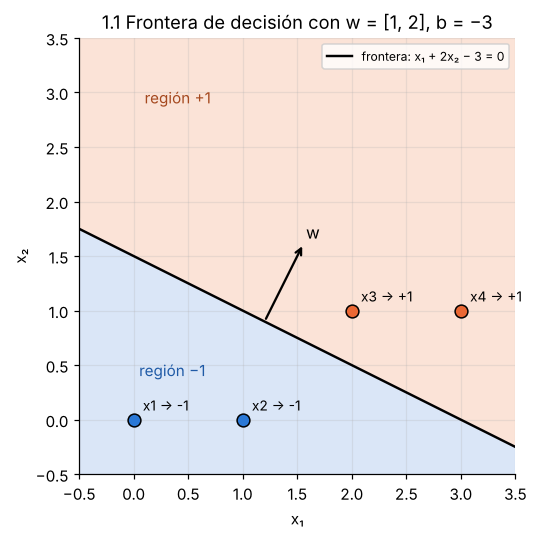

In [2]:
w, b = np.array([1.0, 2.0]), -3.0

def predecir(X, w, b):
    '''Regla del enunciado: +1 si wᵀx + b > 0, −1 si wᵀx + b ≤ 0. X: (n, 2) → (n,).'''
    return np.where(X @ w + b > 0, 1, -1)

puntos = np.array([[0, 0], [1, 0], [2, 1], [3, 1]], dtype=float)
tabla_11 = pd.DataFrame({"x": [f"({p[0]:g}, {p[1]:g})" for p in puntos],
                         "wᵀx + b": puntos @ w + b,
                         "distancia con signo": (puntos @ w + b) / np.linalg.norm(w),
                         "clase": predecir(puntos, w, b)},
                        index=[f"x{i}" for i in range(1, 5)])
display(tabla_11)

g = np.linspace(-0.5, 3.5, 400)
X1, X2 = np.meshgrid(g, g)
Z = predecir(np.c_[X1.ravel(), X2.ravel()], w, b).reshape(X1.shape)

fig, ax = plt.subplots(figsize=(6, 5))
ax.contourf(X1, X2, Z, levels=[-2, 0, 2], cmap=FONDO, alpha=0.9)
ax.plot(g, (3 - g) / 2, color="black", lw=1.6, label="frontera: x₁ + 2x₂ − 3 = 0")
for nombre, p, c in zip(tabla_11.index, puntos, tabla_11["clase"]):
    ax.scatter(*p, s=70, color=AZUL if c < 0 else NARANJA, edgecolor="black", zorder=3)
    ax.annotate(f"{nombre} → {c:+d}", p, textcoords="offset points", xytext=(6, 6), fontsize=9)
pie = np.array([1.2, 0.9])                       # un punto de la recta: 1.2 + 2(0.9) − 3 = 0
ax.annotate("", pie + w / np.linalg.norm(w) * 0.8, pie, arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(*(pie + w / np.linalg.norm(w) * 0.85), "w", fontsize=11)
ax.text(0.1, 2.9, "región +1", fontsize=10, color="#a5491f"); ax.text(0.05, 0.4, "región −1", fontsize=10, color="#1f5aa6")
ax.set_xlim(-0.5, 3.5); ax.set_ylim(-0.5, 3.5); ax.set_aspect("equal")
ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("1.1 Frontera de decisión con w = [1, 2], b = −3")
plt.tight_layout(); plt.savefig("fig_11_frontera.png", dpi=150); plt.show()

## 1.2 Actualización del perceptrón: el margen siempre sube

**Definición.** El margen de $(x_i,y_i)$ es $m_i=y_i(w^\top x_i+b)$. Es positivo cuando $w^\top x_i+b$ tiene el mismo signo que la etiqueta, es decir, cuando el punto está del lado correcto. Si $(x_i,y_i)$ está mal clasificado, se aplica

$$w_{\text{nuevo}}=w+\eta\,y_ix_i,\qquad b_{\text{nuevo}}=b+\eta\,y_i,\qquad \eta>0 .$$

**Demostración.** Se sustituyen los parámetros nuevos en la definición del margen:

$$\begin{aligned}
m_{i,\text{nuevo}}&=y_i\big(w_{\text{nuevo}}^\top x_i+b_{\text{nuevo}}\big)\\
&=y_i\big((w+\eta y_ix_i)^\top x_i+b+\eta y_i\big) &&\text{sustitución}\\
&=y_i\big(w^\top x_i+b\big)+\eta\,y_i^2\,x_i^\top x_i+\eta\,y_i^2 &&\text{distributiva}\\
&=m_i+\eta\,y_i^2\big(\|x_i\|_2^2+1\big) &&x_i^\top x_i=\|x_i\|_2^2\\
&=m_i+\eta\big(\|x_i\|_2^2+1\big) &&y_i\in\{-1,+1\}\Rightarrow y_i^2=1.\qquad\blacksquare
\end{aligned}$$

**Qué implica.** Como $\eta>0$ y $\|x_i\|_2^2+1\ge1$, el incremento $\eta(\|x_i\|^2+1)$ es **siempre positivo**: después de la actualización, el margen de la observación corregida **sube**, es decir, la frontera se mueve hacia el lado que la clasifica bien. El $+1$ viene del sesgo $b$, que se actualiza como si $x_i$ tuviera una coordenada extra igual a 1.

Dos matices:

- **Subir no garantiza quedar bien clasificada en un solo paso.** Queda bien si $m_{i,\text{nuevo}}>0$, es decir, si $\eta(\|x_i\|^2+1)>-m_i$. Si el punto estaba muy del lado equivocado o $\eta$ es pequeño, puede requerir varias pasadas.
- **El cambio es local.** La actualización mejora el margen de esa observación, pero puede empeorar el de otras. Por eso el perceptrón recorre los datos varias veces; si los datos son linealmente separables, termina en un número finito de actualizaciones (teorema de convergencia de Novikoff).

In [3]:
# Comprobación numérica de m_nuevo = m + η(‖x‖² + 1) con observaciones, pesos y η al azar
rng = np.random.default_rng(SEMILLA)
errores = []
for _ in range(1000):
    x_i, w0, b0 = rng.normal(size=2), rng.normal(size=2), rng.normal()
    y_i, eta = rng.choice([-1, 1]), rng.uniform(0.01, 2)
    m = y_i * (w0 @ x_i + b0)
    w1, b1 = w0 + eta * y_i * x_i, b0 + eta * y_i
    m_nuevo = y_i * (w1 @ x_i + b1)
    errores.append(abs(m_nuevo - (m + eta * (x_i @ x_i + 1))))
print(f"1000 casos al azar: máx |m_nuevo − (m + η(‖x‖² + 1))| = {max(errores):.1e}")

1000 casos al azar: máx |m_nuevo − (m + η(‖x‖² + 1))| = 3.6e-15


## 1.3 Ejercicio numérico

Con $w=[0,0]^\top$, $b=0$, $\eta=0.5$, $x=[2,1]^\top$ y $y=+1$:

1. **¿Hay que actualizar?** $w^\top x+b=0\cdot2+0\cdot1+0=0$. Por la regla, $0\le0$ da $\hat y=-1$, distinto de $y=+1$: **está mal clasificada y sí se actualiza**. Su margen es $m=y(w^\top x+b)=1\cdot0=0$, que no es positivo.
2. **Nuevos parámetros.**
$$w_{\text{nuevo}}=\begin{bmatrix}0\\0\end{bmatrix}+0.5\cdot(+1)\begin{bmatrix}2\\1\end{bmatrix}=\begin{bmatrix}1\\0.5\end{bmatrix},\qquad b_{\text{nuevo}}=0+0.5\cdot(+1)=0.5 .$$
3. **Nuevo margen**, de dos formas:
$$m_{\text{nuevo}}=y\,(w_{\text{nuevo}}^\top x+b_{\text{nuevo}})=1\cdot(1\cdot2+0.5\cdot1+0.5)=3,$$
$$m_{\text{nuevo}}=m+\eta(\|x\|^2+1)=0+0.5\,(4+1+1)=3 .$$

Ahora $w_{\text{nuevo}}^\top x+b_{\text{nuevo}}=3>0$, así que $\hat y=+1=y$: quedó bien clasificada en una sola actualización.

In [4]:
def paso_perceptron(w, b, x, y, eta):
    '''Una aplicación de la regla del perceptrón sobre (x, y). Devuelve w, b y si hubo actualización.'''
    y_hat = 1 if w @ x + b > 0 else -1
    if y_hat != y:
        return w + eta * y * x, b + eta * y, True
    return w, b, False


w0, b0, eta = np.array([0.0, 0.0]), 0.0, 0.5
x13, y13 = np.array([2.0, 1.0]), 1
w1, b1, actualizo = paso_perceptron(w0, b0, x13, y13, eta)
m0, m1 = y13 * (w0 @ x13 + b0), y13 * (w1 @ x13 + b1)
print(f"wᵀx + b antes = {w0 @ x13 + b0:g} → ŷ = {predecir(x13[None], w0, b0)[0]:+d}, y = {y13:+d}: ¿se actualiza? {actualizo}")
print(f"w_nuevo = {w1}, b_nuevo = {b1:g}")
print(f"margen antes = {m0:g}, margen después = {m1:g}, fórmula m + η(‖x‖² + 1) = {m0 + eta * (x13 @ x13 + 1):g}")
print(f"predicción nueva: ŷ = {predecir(x13[None], w1, b1)[0]:+d}")

wᵀx + b antes = 0 → ŷ = -1, y = +1: ¿se actualiza? True
w_nuevo = [1.  0.5], b_nuevo = 0.5
margen antes = 0, margen después = 3, fórmula m + η(‖x‖² + 1) = 3
predicción nueva: ŷ = +1


### Comprobación adicional: el perceptrón completo

Para ver la regla en acción, se entrena el perceptrón implementado a mano sobre 60 puntos linealmente separables con un margen estrecho: recorre los datos, actualiza cada vez que encuentra un error y se detiene cuando una pasada completa no tiene errores. No lo pide el enunciado; ilustra el resultado de 1.2.

Errores por pasada: [7, 2, 1, 0]   →  w = [1.092 1.804], b = -1.000
Exactitud final sobre los 60 puntos: 1.00


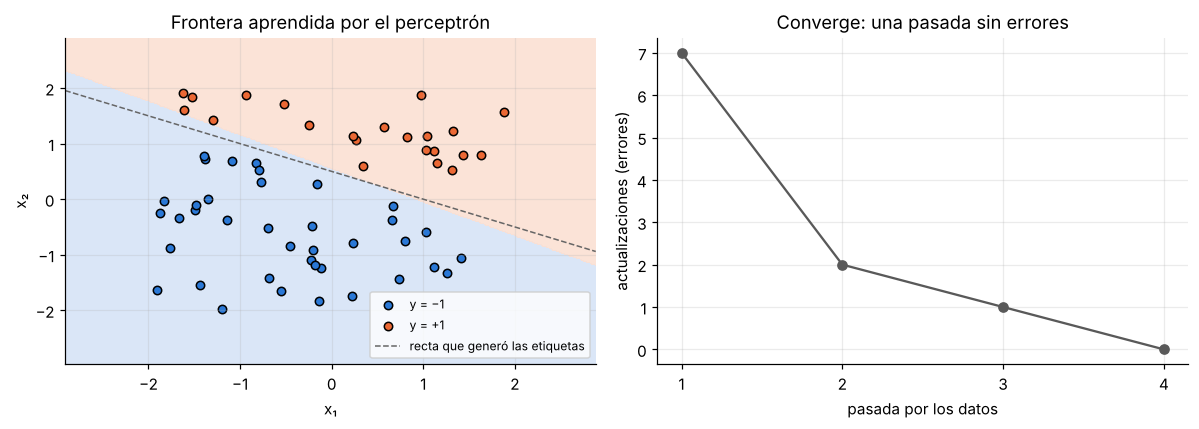

In [5]:
def entrenar_perceptron(X, y, eta=0.5, max_pasadas=100):
    '''Perceptrón con la regla del enunciado. X: (n, 2), y ∈ {−1, +1}. Devuelve w, b y errores por pasada.'''
    w, b, historial = np.zeros(X.shape[1]), 0.0, []
    for _ in range(max_pasadas):
        errores = 0
        for x_i, y_i in zip(X, y):
            w, b, actualizo = paso_perceptron(w, b, x_i, y_i, eta)
            errores += actualizo
        historial.append(errores)
        if errores == 0:
            break
    return w, b, historial


# 60 puntos etiquetados por la recta x₁ + 2x₂ − 1 = 0, quitando los que quedan a menos de 0.2 de ella:
# así los datos son linealmente separables, con un margen estrecho que obliga a varias pasadas.
rng = np.random.default_rng(SEMILLA)
X_u = rng.uniform(-2, 2, (120, 2))
dist = (X_u @ np.array([1.0, 2.0]) - 1) / np.sqrt(5)
lejos = np.abs(dist) > 0.2
Xp, yp = X_u[lejos][:60], np.where(dist[lejos][:60] > 0, 1, -1)
w_p, b_p, historial = entrenar_perceptron(Xp, yp)
print(f"Errores por pasada: {historial}   →  w = {np.round(w_p, 3)}, b = {b_p:.3f}")
print(f"Exactitud final sobre los 60 puntos: {np.mean(predecir(Xp, w_p, b_p) == yp):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
gx = np.linspace(Xp[:, 0].min() - 1, Xp[:, 0].max() + 1, 300)
gy = np.linspace(Xp[:, 1].min() - 1, Xp[:, 1].max() + 1, 300)
GX, GY = np.meshgrid(gx, gy)
ax[0].contourf(GX, GY, predecir(np.c_[GX.ravel(), GY.ravel()], w_p, b_p).reshape(GX.shape),
               levels=[-2, 0, 2], cmap=FONDO, alpha=0.9)
ax[0].scatter(*Xp[yp < 0].T, color=AZUL, edgecolor="black", s=30, label="y = −1")
ax[0].scatter(*Xp[yp > 0].T, color=NARANJA, edgecolor="black", s=30, label="y = +1")
ax[0].plot(gx, (1 - gx) / 2, "--", color="0.4", lw=1, label="recta que generó las etiquetas")
ax[0].set_ylim(gy.min(), gy.max())
ax[0].set_title("Frontera aprendida por el perceptrón"); ax[0].legend(fontsize=8)
ax[0].set_xlabel("x₁"); ax[0].set_ylabel("x₂")
ax[1].plot(range(1, len(historial) + 1), historial, "o-", color=GRIS)
ax[1].set_xticks(range(1, len(historial) + 1))
ax[1].set_xlabel("pasada por los datos"); ax[1].set_ylabel("actualizaciones (errores)")
ax[1].set_title("Converge: una pasada sin errores")
plt.tight_layout(); plt.savefig("fig_13_perceptron.png", dpi=150); plt.show()

# Punto 2. Clasificación por los $k$ vecinos más cercanos

## 2.1 Cálculo manual

Con $q=(1,1)$ y $d(q,x_i)=\sqrt{(q_1-x_{i,1})^2+(q_2-x_{i,2})^2}$:

| Obs. | $x_i$ | Clase | $d(q,x_i)$ |
|---|---|---|---|
| $x_1$ | $(0,0)$ | A | $\sqrt{1+1}=\sqrt2\approx1.414$ |
| $x_2$ | $(1,0)$ | A | $\sqrt{0+1}=1$ |
| $x_3$ | $(3,1)$ | B | $\sqrt{4+0}=2$ |
| $x_4$ | $(0,3)$ | B | $\sqrt{1+4}=\sqrt5\approx2.236$ |
| $x_5$ | $(1.1,1.1)$ | B | $\sqrt{0.01+0.01}=\sqrt{0.02}\approx0.141$ |

**Orden de más cercano a más lejano:** $x_5$ (B, 0.141), $x_2$ (A, 1), $x_1$ (A, 1.414), $x_3$ (B, 2), $x_4$ (B, 2.236).

| $k$ | Vecinos | Votos | Predicción |
|---|---|---|---|
| 1 | $x_5$ | B: 1 | **B** |
| 3 | $x_5,x_2,x_1$ | A: 2, B: 1 | **A** |
| 5 | todos | A: 2, B: 3 | **B** |

**Por qué cambia con $k$.** La predicción depende de qué puntos entran en la votación. Con $k=1$ decide solo $x_5$, que está casi encima de $q$. Con $k=3$ entran $x_2$ y $x_1$, de clase A, y ganan por mayoría. Con $k=5$ entran todos, y como hay más B que A en el conjunto, gana B sin importar la cercanía. Un $k$ pequeño es muy **local** (sensible a un solo punto, incluso a uno ruidoso); un $k$ grande es más **global** y tiende hacia la clase mayoritaria.

In [6]:
X21 = np.array([[0, 0], [1, 0], [3, 1], [0, 3], [1.1, 1.1]])
c21 = np.array(["A", "A", "B", "B", "B"])
q = np.array([1.0, 1.0])

d = np.sqrt(((X21 - q)**2).sum(axis=1))
orden = np.argsort(d)
display(pd.DataFrame({"x": [f"({p[0]:g}, {p[1]:g})" for p in X21], "clase": c21, "distancia": d},
                     index=[f"x{i}" for i in range(1, 6)]).iloc[orden])

filas = []
for k in [1, 3, 5]:
    vecinos = orden[:k]
    votos = pd.Series(c21[vecinos]).value_counts()
    manual = votos.idxmax()
    sk = KNeighborsClassifier(n_neighbors=k).fit(X21, c21).predict(q[None])[0]
    filas.append({"k": k, "vecinos": ", ".join(f"x{i + 1}" for i in vecinos),
                  "votos": dict(votos), "predicción manual": manual, "scikit-learn": sk})
display(pd.DataFrame(filas).set_index("k"))

,x,clase,distancia
x5,"(1.1, 1.1)",B,0.1414
x2,"(1, 0)",A,1.0000
x1,"(0, 0)",A,1.4142
x3,"(3, 1)",B,2.0000
x4,"(0, 3)",B,2.2361


,vecinos,votos,predicción manual,scikit-learn
k,,,,
1,x5,{'B': 1},B,B
3,"x5, x2, x1","{'A': 2, 'B': 1}",A,A
5,"x5, x2, x1, x3, x4","{'B': 3, 'A': 2}",B,B


## 2.2 Implementación con `make_moons`

Se generan 300 puntos con `noise=0.20` y `random_state=42`, se separa 70 % para entrenamiento y 30 % para prueba **estratificando** (las dos clases quedan en la misma proporción en cada parte) y se entrena `KNeighborsClassifier` con $k\in\{1,5,15\}$.

In [7]:
X, y = make_moons(n_samples=300, noise=0.20, random_state=SEMILLA)
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
print(f"Entrenamiento: {X_ent.shape}, clases {np.bincount(y_ent)}   Prueba: {X_pru.shape}, clases {np.bincount(y_pru)}")

KS = [1, 5, 15]
modelos, filas = {}, []
for k in KS:
    modelos[k] = KNeighborsClassifier(n_neighbors=k).fit(X_ent, y_ent)
    filas.append({"k": k,
                  "exactitud entrenamiento": accuracy_score(y_ent, modelos[k].predict(X_ent)),
                  "exactitud prueba": accuracy_score(y_pru, modelos[k].predict(X_pru))})
tabla_knn = pd.DataFrame(filas).set_index("k")
tabla_knn["diferencia"] = tabla_knn["exactitud entrenamiento"] - tabla_knn["exactitud prueba"]
display(tabla_knn)

Entrenamiento: (210, 2), clases [105 105]   Prueba: (90, 2), clases [45 45]


,exactitud entrenamiento,exactitud prueba,diferencia
k,,,
1,1.0000,0.9333,0.0667
5,0.9571,0.9556,0.0016
15,0.9571,0.9333,0.0238


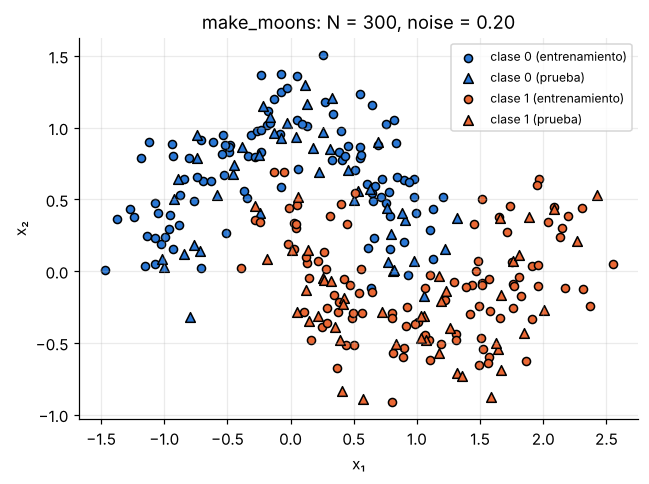

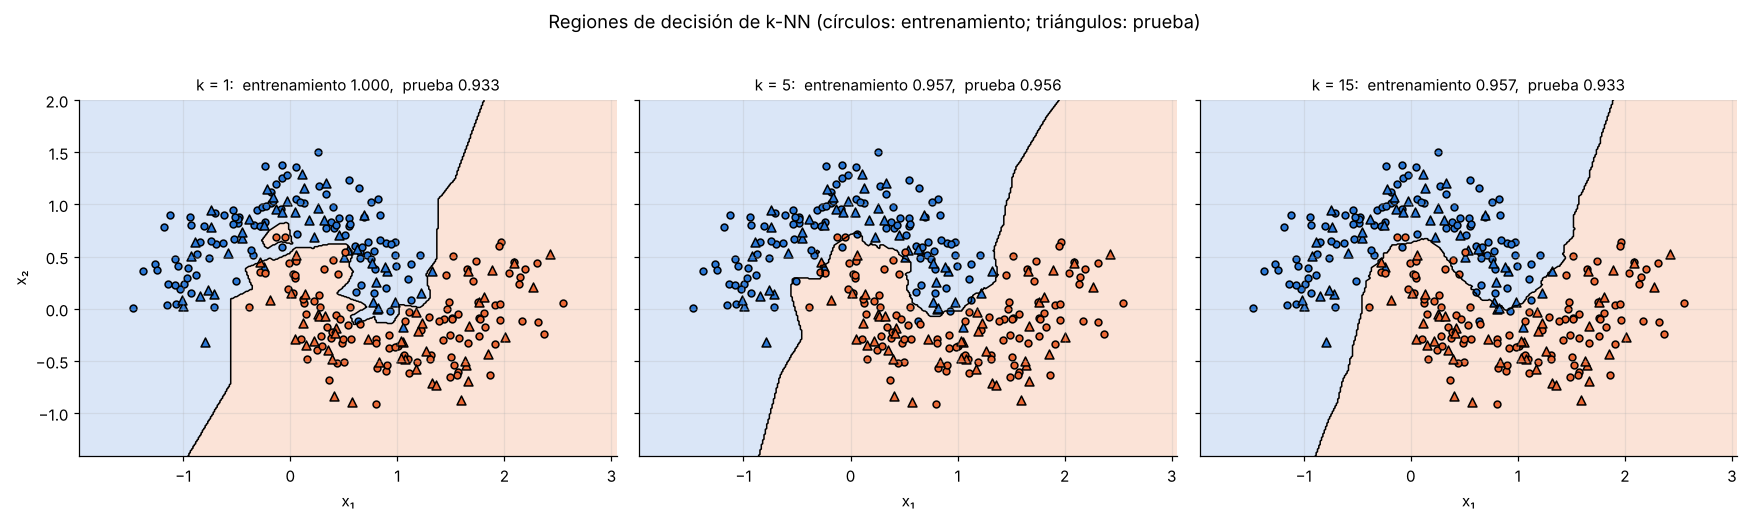

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for clase, color in [(0, AZUL), (1, NARANJA)]:
    ax.scatter(*X_ent[y_ent == clase].T, color=color, edgecolor="black", s=28, label=f"clase {clase} (entrenamiento)")
    ax.scatter(*X_pru[y_pru == clase].T, color=color, edgecolor="black", marker="^", s=40, label=f"clase {clase} (prueba)")
ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.legend(fontsize=8)
ax.set_title("make_moons: N = 300, noise = 0.20")
plt.tight_layout(); plt.savefig("fig_22_datos.png", dpi=150); plt.show()

gx = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 400)
gy = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 400)
GX, GY = np.meshgrid(gx, gy)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for eje, k in zip(ax, KS):
    Zk = modelos[k].predict(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)
    eje.contourf(GX, GY, Zk, levels=[-0.5, 0.5, 1.5], cmap=FONDO, alpha=0.9)
    eje.contour(GX, GY, Zk, levels=[0.5], colors="black", linewidths=1)
    for clase, color in [(0, AZUL), (1, NARANJA)]:
        eje.scatter(*X_ent[y_ent == clase].T, color=color, edgecolor="black", s=20)
        eje.scatter(*X_pru[y_pru == clase].T, color=color, edgecolor="black", marker="^", s=34)
    f = tabla_knn.loc[k]
    eje.set_title(f"k = {k}:  entrenamiento {f['exactitud entrenamiento']:.3f},  prueba {f['exactitud prueba']:.3f}", fontsize=10)
    eje.set_xlabel("x₁")
ax[0].set_ylabel("x₂")
plt.suptitle("Regiones de decisión de k-NN (círculos: entrenamiento; triángulos: prueba)", y=1.02)
plt.tight_layout(); plt.savefig("fig_22_regiones.png", dpi=150, bbox_inches="tight"); plt.show()

## 2.3 Elección de $k$ con validación cruzada

El enunciado pide explicar por qué el mejor $k$ se escoge con validación y no con prueba. Para mostrarlo, se hace la selección formal: validación cruzada estratificada de 5 particiones **solo sobre el entrenamiento**, para $k=1,\dots,40$. El conjunto de prueba se usa una sola vez al final, para reportar el desempeño del $k$ escogido.

k elegido por validación cruzada: 11  (exactitud de validación 0.962 ± 0.032)
Exactitud en prueba de ese modelo, medida una sola vez: 0.967
Exactitud de validación para k = 1, 5, 15: {1: np.float64(0.938), 5: np.float64(0.952), 15: np.float64(0.957)}


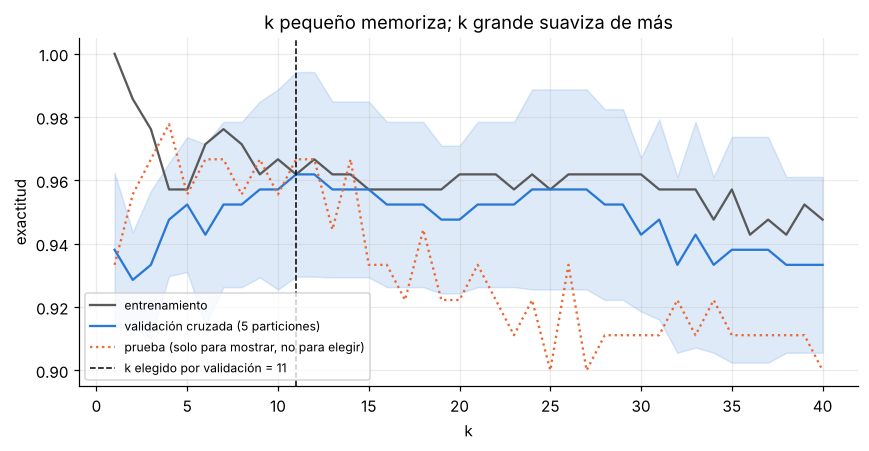

In [9]:
k_rango = np.arange(1, 41)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_media = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=k), X_ent, y_ent, cv=cv).mean() for k in k_rango])
cv_std = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=k), X_ent, y_ent, cv=cv).std() for k in k_rango])
exact_ent = np.array([accuracy_score(y_ent, KNeighborsClassifier(n_neighbors=k).fit(X_ent, y_ent).predict(X_ent)) for k in k_rango])
exact_pru = np.array([accuracy_score(y_pru, KNeighborsClassifier(n_neighbors=k).fit(X_ent, y_ent).predict(X_pru)) for k in k_rango])

k_cv = int(k_rango[np.argmax(cv_media)])
modelo_final = KNeighborsClassifier(n_neighbors=k_cv).fit(X_ent, y_ent)
print(f"k elegido por validación cruzada: {k_cv}  (exactitud de validación {cv_media.max():.3f} ± {cv_std[np.argmax(cv_media)]:.3f})")
print(f"Exactitud en prueba de ese modelo, medida una sola vez: {accuracy_score(y_pru, modelo_final.predict(X_pru)):.3f}")
print("Exactitud de validación para k = 1, 5, 15:", {k: round(cv_media[k - 1], 3) for k in KS})

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(k_rango, exact_ent, color=GRIS, label="entrenamiento")
ax.plot(k_rango, cv_media, color=AZUL, label="validación cruzada (5 particiones)")
ax.fill_between(k_rango, cv_media - cv_std, cv_media + cv_std, color=AZUL, alpha=0.15)
ax.plot(k_rango, exact_pru, ":", color=NARANJA, label="prueba (solo para mostrar, no para elegir)")
ax.axvline(k_cv, color="black", ls="--", lw=1, label=f"k elegido por validación = {k_cv}")
ax.set_xlabel("k"); ax.set_ylabel("exactitud"); ax.legend(fontsize=8)
ax.set_title("k pequeño memoriza; k grande suaviza de más")
plt.tight_layout(); plt.savefig("fig_23_validacion.png", dpi=150); plt.show()

### Interpretación

- **$k$ muy pequeño ($k=1$).** Cada punto de entrenamiento es su propio vecino, así que la exactitud de entrenamiento es 1: el modelo **memoriza**. La frontera es irregular y forma «islas» alrededor de los puntos ruidosos que caen del lado de la otra clase. Tiene poco sesgo y mucha varianza: cambia mucho si cambian unos pocos datos, y generaliza peor.
- **$k$ muy grande.** Cada predicción promedia muchos vecinos, incluidos puntos lejanos de la otra luna. La frontera se suaviza demasiado y pierde la forma curva; en el extremo $k=N$ predice siempre la clase mayoritaria. Tiene poca varianza y mucho sesgo (subajuste).
- **En esta evaluación generalizó mejor $k=5$:** tiene la mayor exactitud de prueba (0.956) y casi la misma que en entrenamiento (0.957), así que no está memorizando. $k=1$ llega a 1.000 en entrenamiento pero baja a 0.933 en prueba (sobreajuste: 6.7 puntos de diferencia), y $k=15$ queda en 0.933 en prueba con una frontera más rígida. Con solo 90 datos de prueba, sin embargo, 0.956 frente a 0.933 son dos puntos mal clasificados de diferencia; por eso esta comparación sirve para describir lo que pasó, no para escoger $k$.
- **La selección formal** con validación cruzada sobre el entrenamiento escoge $k=11$ (exactitud de validación 0.962), un valor intermedio, coherente con lo anterior. Medido una sola vez en prueba, ese modelo da 0.967.
- **Por qué validación y no prueba.** El conjunto de prueba debe simular datos que el modelo nunca ha visto. Si se usa para escoger $k$, ese conjunto pasa a formar parte del entrenamiento (del hiperparámetro), y su exactitud deja de ser una estimación honesta: sale optimista, porque se escogió precisamente el $k$ al que mejor le fue en esos 90 datos (fuga de información). Con 90 datos, además, la exactitud de prueba tiene un error de muestreo de unos $\pm3$ puntos, así que diferencias pequeñas entre valores de $k$ pueden ser azar. La validación cruzada elige $k$ usando solo el entrenamiento, promediando 5 particiones para reducir esa variabilidad, y deja la prueba para una única medición final.

# Punto 3. Evaluación de un clasificador binario

$$y=[0,0,0,0,1,1,1,1,1,1],\qquad \hat y=[0,1,0,0,1,0,1,1,0,1],$$

con la clase 1 como positiva.

## 3.1 Matriz de confusión

Se compara posición por posición:

| $i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| $y$ | 0 | 0 | 0 | 0 | 1 | 1 | 1 | 1 | 1 | 1 |
| $\hat y$ | 0 | 1 | 0 | 0 | 1 | 0 | 1 | 1 | 0 | 1 |
| Tipo | TN | **FP** | TN | TN | TP | **FN** | TP | TP | **FN** | TP |

Conteos: $TP=4$, $TN=3$, $FP=1$, $FN=2$ (suman 10). Con filas = clase real y columnas = clase predicha:

| | Predicho 0 | Predicho 1 |
|---|---|---|
| **Real 0** | $TN=3$ | $FP=1$ |
| **Real 1** | $FN=2$ | $TP=4$ |

## 3.2 Métricas

| Métrica | Cálculo | Valor | Qué evalúa |
|---|---|---|---|
| Exactitud | $\frac{4+3}{4+3+1+2}=\frac{7}{10}$ | $0.700$ | Fracción de todas las predicciones que son correctas |
| Precisión | $\frac{4}{4+1}=\frac45$ | $0.800$ | De lo que el modelo dijo «positivo», cuánto lo era: confiabilidad de una alarma |
| Exhaustividad (recall) | $\frac{4}{4+2}=\frac23$ | $0.667$ | De los positivos reales, cuántos encontró: capacidad de no dejar pasar positivos |
| F1 | $\frac{2(0.8)(2/3)}{0.8+2/3}=\frac{16/15}{22/15}=\frac{8}{11}$ | $0.727$ | Media armónica de precisión y exhaustividad: solo es alta si las dos lo son |

El F1 también se puede escribir como $\frac{2TP}{2TP+FP+FN}=\frac{8}{8+1+2}=\frac8{11}$. Este clasificador se equivoca más por omisión (2 positivos que no detectó) que por falsas alarmas (1).

,Predicho 0,Predicho 1
Real 0,3,1
Real 1,2,4


TP = 4, TN = 3, FP = 1, FN = 2


,manual,scikit-learn
accuracy,0.7000,0.7000
precision,0.8000,0.8000
recall,0.6667,0.6667
f1,0.7273,0.7273


Los cálculos manuales coinciden con scikit-learn.


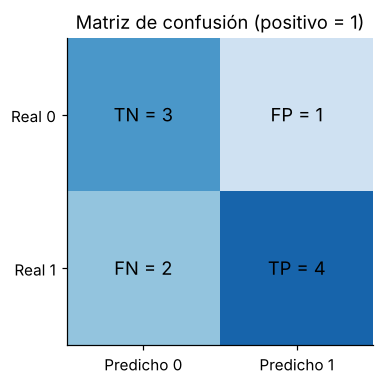

In [10]:
y_real = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

cm = confusion_matrix(y_real, y_pred, labels=[0, 1])        # filas: real, columnas: predicho
tn, fp, fn, tp = cm.ravel()
display(pd.DataFrame(cm, index=["Real 0", "Real 1"], columns=["Predicho 0", "Predicho 1"]))
print(f"TP = {tp}, TN = {tn}, FP = {fp}, FN = {fn}")

manual = {"accuracy": (tp + tn) / (tp + tn + fp + fn), "precision": tp / (tp + fp),
          "recall": tp / (tp + fn)}
manual["f1"] = 2 * manual["precision"] * manual["recall"] / (manual["precision"] + manual["recall"])
sk = {"accuracy": accuracy_score(y_real, y_pred), "precision": precision_score(y_real, y_pred, pos_label=1),
      "recall": recall_score(y_real, y_pred, pos_label=1), "f1": f1_score(y_real, y_pred, pos_label=1)}
tabla_3 = pd.DataFrame({"manual": manual, "scikit-learn": sk})
display(tabla_3)
assert np.allclose(tabla_3["manual"], tabla_3["scikit-learn"])
print("Los cálculos manuales coinciden con scikit-learn.")

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() + 1)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{['TN', 'FP', 'FN', 'TP'][2 * i + j]} = {v}", ha="center", va="center", fontsize=12)
ax.set_xticks([0, 1], ["Predicho 0", "Predicho 1"]); ax.set_yticks([0, 1], ["Real 0", "Real 1"])
ax.grid(False); ax.set_title("Matriz de confusión (positivo = 1)")
plt.tight_layout(); plt.savefig("fig_31_confusion.png", dpi=150); plt.show()

## 3.3 Dos situaciones en las que la exactitud sola engaña

**1. Clases desbalanceadas.** Si de 1000 transacciones solo 10 son fraude, un modelo que **siempre** responde «no fraude» tiene exactitud de $990/1000=0.99$ y no detecta ningún fraude: su exhaustividad es 0. La exactitud la domina la clase mayoritaria.

**2. Errores con costos distintos.** En un tamizaje médico, dejar pasar un enfermo (FN) es mucho más grave que una falsa alarma (FP), que se corrige con otro examen. Dos modelos con la misma exactitud pueden tener errores muy distintos: uno con 10 FN y 0 FP, y otro con 0 FN y 10 FP, tienen la misma exactitud, pero solo el segundo sirve para tamizaje. Ahí importan la exhaustividad (y el F1), no la exactitud.

La celda siguiente lo muestra con números.

In [11]:
# Situación 1: 1000 casos, 10 positivos; el modelo siempre dice 0
y_d = np.r_[np.zeros(990, int), np.ones(10, int)]
siempre_0 = np.zeros(1000, int)
# Situación 2: 100 pacientes, 20 enfermos; dos modelos con la misma exactitud
y_m = np.r_[np.zeros(80, int), np.ones(20, int)]
modelo_a = np.r_[np.zeros(80, int), np.ones(10, int), np.zeros(10, int)]    # 10 FN, 0 FP
modelo_b = np.r_[np.zeros(70, int), np.ones(10, int), np.ones(20, int)]     # 0 FN, 10 FP

filas = {}
for nombre, yt, yp in [("Fraude: siempre «no»", y_d, siempre_0),
                       ("Tamizaje: modelo A (10 FN)", y_m, modelo_a),
                       ("Tamizaje: modelo B (10 FP)", y_m, modelo_b)]:
    filas[nombre] = {"exactitud": accuracy_score(yt, yp),
                     "precisión": precision_score(yt, yp, zero_division=0),
                     "exhaustividad": recall_score(yt, yp), "F1": f1_score(yt, yp, zero_division=0)}
display(pd.DataFrame(filas).T)

,exactitud,precisión,exhaustividad,F1
Fraude: siempre «no»,0.9900,0.0000,0.0000,0.0000
Tamizaje: modelo A (10 FN),0.9000,1.0000,0.5000,0.6667
Tamizaje: modelo B (10 FP),0.9000,0.6667,1.0000,0.8000


# Conclusiones

- **Perceptrón.** La frontera $x_1+2x_2-3=0$ separa $x_1,x_2$ (clase $-1$) de $x_3,x_4$ (clase $+1$). La regla de actualización aumenta el margen de la observación corregida en $\eta(\|x_i\|^2+1)>0$, siempre; puede necesitar varias actualizaciones para quedar del lado correcto. En el ejemplo numérico, el punto con $w^\top x+b=0$ cuenta como error (la regla manda el 0 a la clase $-1$), y una sola actualización lo deja con margen 3.
- **k-NN.** Para $q=(1,1)$ la predicción cambia con $k$: B, A, B para $k=1,3,5$. Con `make_moons`, $k=1$ memoriza (exactitud 1.000 en entrenamiento, 0.933 en prueba), $k=15$ suaviza de más (0.933 en prueba) y $k=5$ generaliza mejor (0.956 en prueba, casi igual a entrenamiento). La elección formal se hace con validación cruzada sobre el entrenamiento, que escoge $k=11$; la prueba se usa una sola vez, al final.
- **Evaluación.** Con $TP=4$, $TN=3$, $FP=1$ y $FN=2$: exactitud 0.70, precisión 0.80, exhaustividad 0.67 y F1 0.73, iguales a las de scikit-learn. La exactitud sola engaña con clases desbalanceadas y cuando los errores tienen costos distintos.